# Modelo predador–presa con agentes

El problema predador–presa es un modelo clásico para estudiar la interacción entre dos poblaciones: una de **presas**, que se alimentan de un recurso del entorno y se reproducen, y otra de **predadores**, que las cazan para sobrevivir. En su versión matemática (ecuaciones de Lotka–Volterra) las poblaciones oscilan con un desfase: cuando abundan las presas, los predadores crecen; cuando hay muchos predadores, las presas caen; y con pocas presas, los predadores mueren de hambre.

Aquí construiremos la versión **basada en agentes**: cada presa y cada predador es un individuo que solo percibe su celda, se mueve, gasta energía, come, se reproduce y muere. No hay ninguna ecuación global: la pregunta es si las oscilaciones **emergen** de esas reglas locales.

El modelo tiene tres componentes:

| Componente | Reglas en cada paso |
|---|---|
| **Pasto** <br>(recurso de las presas) | Cada celda tiene o no tiene pasto. Si una presa lo come, la celda queda vacía y vuelve a tener pasto después <br>de *tiempo_rebrote* pasos. |
| **Presa** | Se mueve a una celda vecina al azar, gasta *costo_presa* de energía, come  el pasto de la celda si lo hay (*+ganancia_presa*), <br>muere si su energía llega a 0 y se reproduce con probabilidad *prob_repro_presa*. |
| **Predador** | Se mueve a una celda vecina al azar, gasta *costo_predador*, caza una presa de su celda si la hay (*+ganancia_predador*), <br>muere si su energía llega a 0 y se reproduce con probabilidad *prob_repro_predador*. |

Al reproducirse, un animal **reparte su energía a la mitad** con su cría: la reproducción no crea energía de la nada.

## Instalación

In [37]:
%pip install mesa --quiet

/Users/oh/World/External/Study/UR/AIPS-I/.venv/bin/python: No module named pip
Note: you may need to restart the kernel to use updated packages.


Código preparado para la versión 3.5.1 de mesa

In [38]:
from matplotlib.colors import ListedColormap
import matplotlib.pyplot as plt
import mesa
import numpy as np
import pandas as pd

print("Versión de Mesa:", mesa.__version__)

Versión de Mesa: 3.5.1


## El modelo

Organizamos el código en cuatro clases:

* `Animal`: lo que comparten presas y predadores (moverse, morir, reproducirse).
* `Presa` y `Predador`: heredan de `Animal` y solo definen su propio `step()`.
* `ModeloPredadorPresa`: crea la grilla, el pasto y los animales, y avanza la simulación.

Cabe observar que en este caso el pasto no es un agente: es una matriz de verdadero/falso (`pasto`) más una matriz con los pasos que faltan para que rebrote (`contador`).

In [39]:
class Animal(mesa.Agent):
    """Comportamiento común a presas y predadores."""

    def __init__(self, model, energia):
        super().__init__(model)
        self.energia = energia

    def mover(self):
        """Se mueve a una de las 8 celdas vecinas (vecindad de Moore), elegida al azar."""
        vecinos = self.model.grid.get_neighborhood(self.pos, moore=True, include_center=False)
        self.model.grid.move_agent(self, self.random.choice(vecinos))

    def morir(self, causa):
        """Quita al agente de la grilla y del modelo, y registra la causa."""
        self.model.muertes[(type(self).__name__, causa)] += 1
        self.model.registrar(f"{type(self).__name__} {self.unique_id} murió ({causa}) en {self.pos}")
        self.model.grid.remove_agent(self)
        self.remove()

    def reproducir(self, prob):
        """Con probabilidad prob, crea una cría en la misma celda y le da la mitad de su energía."""
        if self.random.random() < prob:
            self.energia /= 2
            cria = type(self)(self.model, self.energia)
            self.model.grid.place_agent(cria, self.pos)
            self.model.registrar(f"{type(self).__name__} {self.unique_id} tuvo una cría en {self.pos}")


class Presa(Animal):
    def step(self):
        self.mover()
        self.energia -= self.model.costo_presa

        # Comer: el pasto se consume y empieza a rebrotar
        x, y = self.pos
        if self.model.pasto[x, y]:
            self.model.pasto[x, y] = False
            self.model.contador[x, y] = self.model.tiempo_rebrote
            self.energia += self.model.ganancia_presa

        if self.energia <= 0:
            self.morir("hambre")
            return
        self.reproducir(self.model.prob_repro_presa)


class Predador(Animal):
    def step(self):
        self.mover()
        self.energia -= self.model.costo_predador

        # Cazar: si hay presas en la celda, se come una al azar
        presas = [a for a in self.model.grid.get_cell_list_contents([self.pos])
                  if isinstance(a, Presa)]
        if presas:
            victima = self.random.choice(presas)
            self.energia += self.model.ganancia_predador
            victima.morir("cazada")

        if self.energia <= 0:
            self.morir("hambre")
            return
        self.reproducir(self.model.prob_repro_predador)

In [ ]:
from collections import Counter


class ModeloPredadorPresa(mesa.Model):
    def __init__(self, ancho=40, alto=40,
                 n_presas=260, n_predadores=45,
                 tiempo_rebrote=30,
                 ganancia_presa=6, ganancia_predador=30,
                 costo_presa=1, costo_predador=1,
                 prob_repro_presa=0.04, prob_repro_predador=0.05,
                 verbose=False, seed=None):
        super().__init__(rng=seed)
        # Parámetros (se guardan en el modelo para que los agentes los consulten)
        self.ancho, self.alto = ancho, alto
        self.tiempo_rebrote = tiempo_rebrote
        self.ganancia_presa, self.ganancia_predador = ganancia_presa, ganancia_predador
        self.costo_presa, self.costo_predador = costo_presa, costo_predador
        self.prob_repro_presa, self.prob_repro_predador = prob_repro_presa, prob_repro_predador
        self.verbose = verbose
        self.muertes = Counter()

        self.grid = mesa.space.MultiGrid(ancho, alto, torus=True)

        # Pasto inicial: la mitad de las celdas, al azar; las demás con un rebrote pendiente
        self.pasto = np.array([[self.random.random() < 0.5 for _ in range(alto)] for _ in range(ancho)])
        self.contador = np.zeros((ancho, alto), dtype=int)
        for x in range(ancho):
            for y in range(alto):
                if not self.pasto[x, y]:
                    self.contador[x, y] = self.random.randint(1, tiempo_rebrote)
                    # self.contador[x, y] = tiempo_rebrote

        # Animales con energía inicial aleatoria, en posiciones aleatorias
        for _ in range(n_presas):
            self.grid.place_agent(Presa(self, self.random.randint(1, 2 * ganancia_presa)),
                                  (self.random.randrange(ancho), self.random.randrange(alto)))
        for _ in range(n_predadores):
            self.grid.place_agent(Predador(self, self.random.randint(1, 2 * ganancia_predador)),
                                  (self.random.randrange(ancho), self.random.randrange(alto)))

        self.datacollector = mesa.DataCollector(model_reporters={
            "Presas": lambda m: len(m.agents_by_type.get(Presa, [])),
            "Predadores": lambda m: len(m.agents_by_type.get(Predador, [])),
            "Pasto": lambda m: int(m.pasto.sum()),
        })
        self.datacollector.collect(self)   # estado inicial (paso 0)

    def registrar(self, mensaje):
        if self.verbose:
            print(mensaje)

    def crecer_pasto(self):
        """Las celdas sin pasto descuentan un paso; las que llegan a 0 vuelven a tener pasto."""
        sin_pasto = ~self.pasto
        self.contador[sin_pasto] -= 1
        self.pasto[sin_pasto & (self.contador <= 0)] = True

    def step(self):
        self.agents.do("step")   # cada animal actúa una vez, en orden aleatorio
        self.crecer_pasto()
        self.datacollector.collect(self)  # se registra DESPUÉS del paso
        if len(self.agents) == 0:
            self.running = False

## Visualización de la grilla

El fondo muestra el pasto (verde) y la tierra sin pasto (café). Las presas se dibujan como puntos blancos y los predadores como triángulos rojos. Usamos colores fijos (`vmin`, `vmax`) para que el significado de cada color no cambie entre cuadros.

In [41]:
CMAP_PASTO = ListedColormap(["#b08850", "#5fa84a"])   # 0 = tierra, 1 = pasto

def dibujar_grilla(model, ax=None, titulo=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(5, 5))
    # pasto[x, y] -> transponemos para que x sea horizontal e y vertical
    ax.imshow(model.pasto.T, origin="lower", cmap=CMAP_PASTO, vmin=0, vmax=1)

    presas = [a.pos for a in model.agents_by_type.get(Presa, [])]
    predadores = [a.pos for a in model.agents_by_type.get(Predador, [])]
    if presas:
        xs, ys = zip(*presas)
        ax.scatter(xs, ys, s=18, c="white", edgecolors="black", linewidths=0.5, label="Presa")
    if predadores:
        xs, ys = zip(*predadores)
        ax.scatter(xs, ys, s=40, c="red", marker="^", edgecolors="black", linewidths=0.5, label="Predador")

    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(titulo or f"Paso {model.steps}")
    return ax

## Corrida base

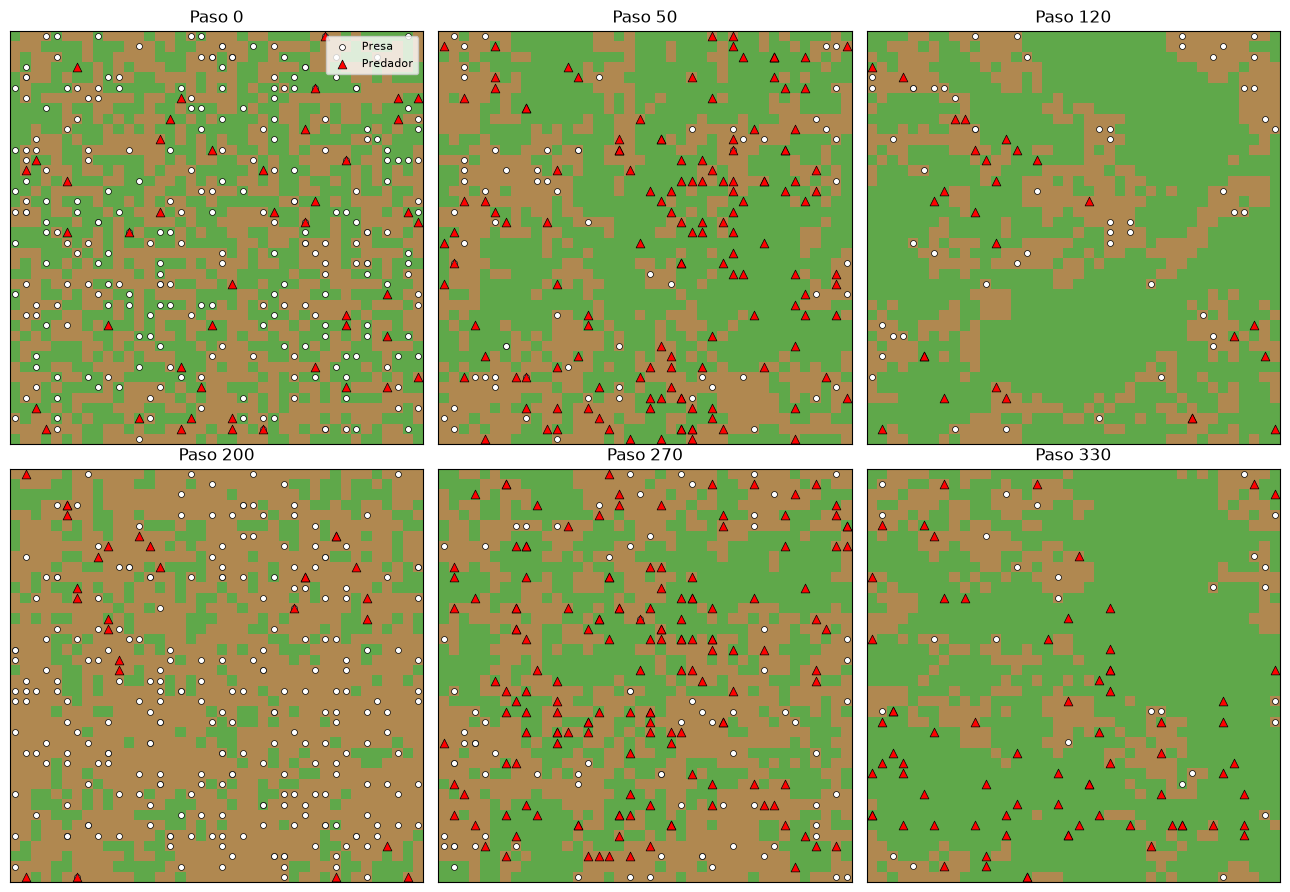

In [42]:
params = dict(
    ancho=40,
    alto=40,
    n_presas=260,
    n_predadores=45,
    tiempo_rebrote=30,
    ganancia_presa=6,
    ganancia_predador=30,
    costo_presa=1,
    costo_predador=1,
    prob_repro_presa=0.04,
    prob_repro_predador=0.05,
)

model = ModeloPredadorPresa(**params, seed=1)

pasos_a_mostrar = [0, 50, 120, 200, 270, 330]
fig, axes = plt.subplots(2, 3, figsize=(13, 9))
axes = axes.flatten()
k = 0
for paso in range(601):
    if paso > 0:
        model.step()
    if paso in pasos_a_mostrar:
        dibujar_grilla(model, axes[k])
        k += 1
axes[0].legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

### Curvas de población

Graficamos las tres series. El pasto se muestra dividido por 4 para que quepa en la misma escala.

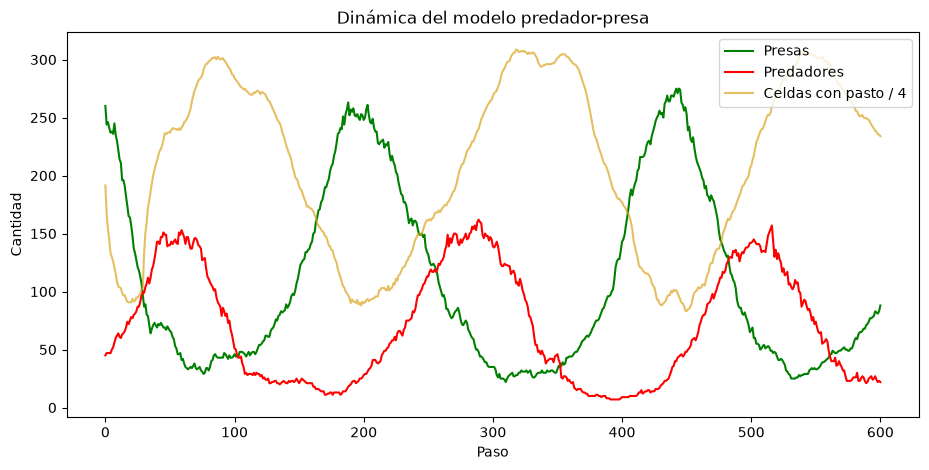

Muertes acumuladas:
  Predador  por hambre : 2045
  Presa     por cazada : 1341
  Presa     por hambre : 1407


In [43]:
datos = model.datacollector.get_model_vars_dataframe()

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(datos["Presas"], color="green", label="Presas")
ax.plot(datos["Predadores"], color="red", label="Predadores")
ax.plot(datos["Pasto"] /4 , color="goldenrod", alpha=0.7, label="Celdas con pasto / 4")
ax.set_xlabel("Paso"); ax.set_ylabel("Cantidad")
ax.set_title("Dinámica del modelo predador-presa")
ax.legend(loc="upper right")
plt.show()

print("Muertes acumuladas:")
for (especie, causa), n in sorted(model.muertes.items()):
    print(f"  {especie:9s} por {causa:7s}: {n}")

### Plano de fase

Otra forma de ver la dinámica es graficar **presas contra predadores**, sin el tiempo. Si hay ciclos, la trayectoria da vueltas alrededor de un punto en lugar de ir y volver por la misma línea.

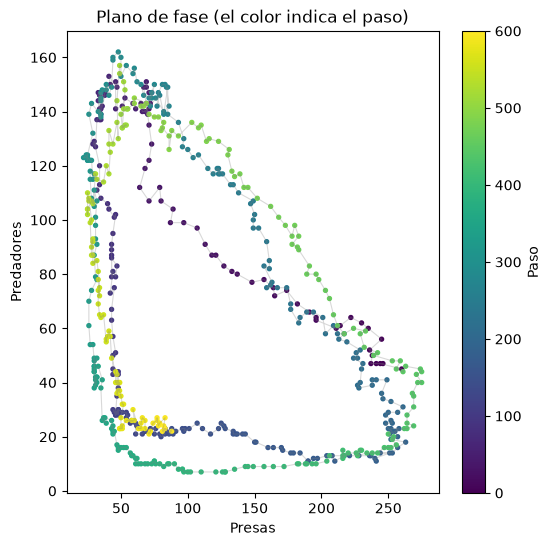

In [44]:
fig, ax = plt.subplots(figsize=(6, 6))
sc = ax.scatter(datos["Presas"], datos["Predadores"], c=datos.index, cmap="viridis", s=8)
ax.plot(datos["Presas"], datos["Predadores"], color="gray", alpha=0.3, lw=0.8)
ax.set_xlabel("Presas"); ax.set_ylabel("Predadores")
ax.set_title("Plano de fase (el color indica el paso)")
plt.colorbar(sc, ax=ax, label="Paso")
plt.show()

### Animación

In [45]:
from IPython.display import HTML
from matplotlib import animation

modelo_anim = ModeloPredadorPresa(**params, seed=1)
fig, ax = plt.subplots(figsize=(5, 5))

def actualizar(_):
    ax.clear()
    modelo_anim.step()
    dibujar_grilla(modelo_anim, ax)

anim = animation.FuncAnimation(fig, actualizar, frames=150, interval=100)
plt.close(fig)
HTML(anim.to_jshtml())

## Herramientas para experimentar

Una sola corrida no basta: el modelo es estocástico y cada semilla da una historia distinta. Estas funciones ayudan a correr muchas simulaciones y resumirlas.

* `correr(params, pasos, seed)` devuelve la tabla de poblaciones de una corrida.
* `barrido(nombre, valores, ...)` varía **un** parámetro, corre varias semillas por valor y resume: en qué fracción de corridas sobreviven ambas especies, y las poblaciones promedio en la segunda mitad de la simulación.

In [46]:
def correr(params, pasos=600, seed=None):
    m = ModeloPredadorPresa(**params, seed=seed)
    for _ in range(pasos):
        if not m.running:
            break
        m.step()
    return m.datacollector.get_model_vars_dataframe()


def barrido(nombre, valores, params_base=params, semillas=range(5), pasos=600):
    filas = []
    for v in valores:
        p = dict(params_base, **{nombre: v})
        for s in semillas:
            d = correr(p, pasos, seed=s)
            segunda_mitad = d.iloc[len(d) // 2:]
            filas.append({
                nombre: v, "semilla": s,
                "coexisten": d["Presas"].iloc[-1] > 0 and d["Predadores"].iloc[-1] > 0,
                "presas_prom": segunda_mitad["Presas"].mean(),
                "predadores_prom": segunda_mitad["Predadores"].mean(),
            })
    tabla = pd.DataFrame(filas)
    return tabla.groupby(nombre)[["coexisten", "presas_prom", "predadores_prom"]].mean()

Ejemplo: varias semillas con los mismos parámetros.

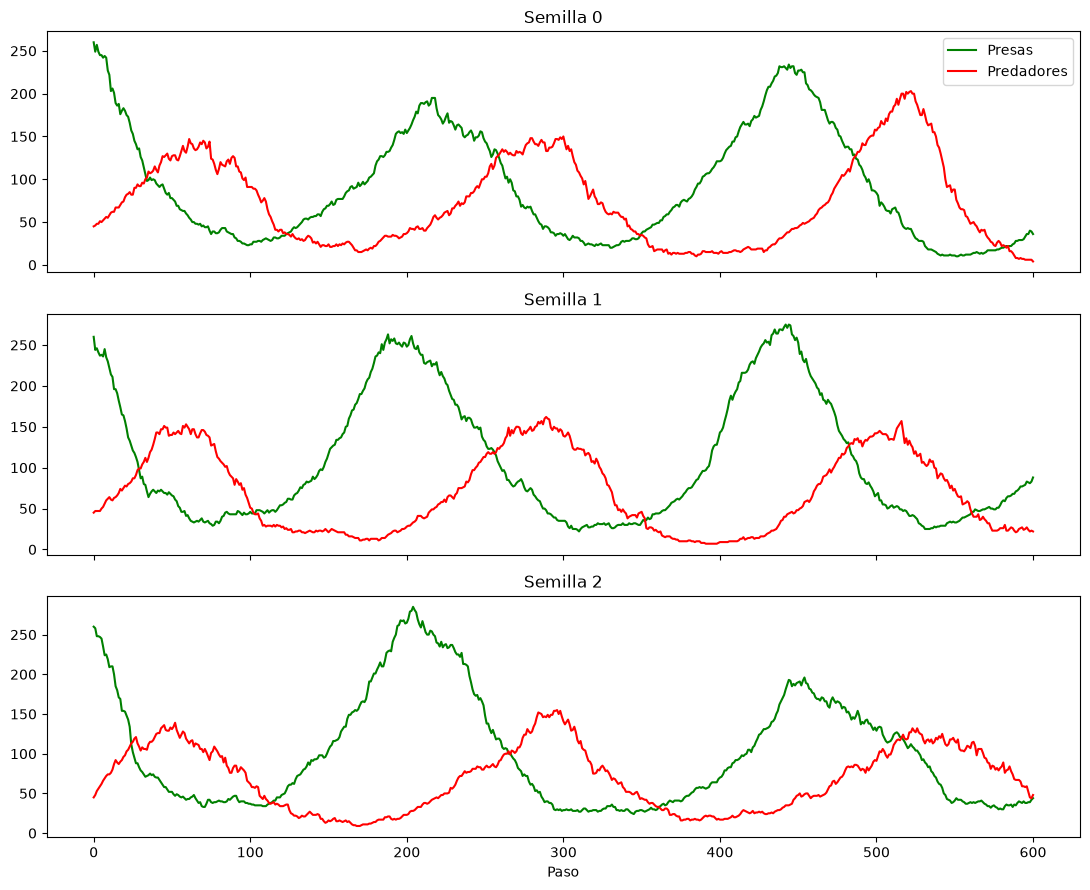

In [47]:
fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True)
for s, ax in zip([0, 1, 2], axes):
    d = correr(params, pasos=600, seed=s)
    ax.plot(d["Presas"], color="green", label="Presas")
    ax.plot(d["Predadores"], color="red", label="Predadores")
    ax.set_title(f"Semilla {s}")
axes[0].legend(); axes[-1].set_xlabel("Paso")
plt.tight_layout(); plt.show()

Ejemplo de barrido: efecto del tiempo de rebrote del pasto.

In [48]:
barrido("tiempo_rebrote", [10, 20, 30, 50, 80])

,coexisten,presas_prom,predadores_prom
tiempo_rebrote,,,
10,0.0,598.646672,63.775813
20,0.6,143.920930,70.328904
30,0.8,123.684385,52.082392
50,1.0,91.171429,42.228571
80,0.0,94.837874,0.000000


---
# Ejercicios

## Parte 1. Entender la dinámica

1. **Desfase entre picos.** En la curva de población de la corrida base, identifique tres picos de presas y el pico de predadores que sigue a cada uno. ¿Cuántos pasos de retraso hay aproximadamente? Explique con las reglas del modelo por qué los predadores alcanzan su máximo *después* de las presas.
2. **El papel del pasto.** ¿Cómo se relaciona la curva del pasto con la de las presas? ¿Cuándo hay más pasto: cuando hay muchas presas o pocas? ¿Qué limita el crecimiento de las presas cuando no hay predadores cerca?
3. **Plano de fase.** Describa la forma de la trayectoria. ¿Gira en sentido horario o antihorario? Interprete cada cuadrante del giro (muchas presas y pocos predadores, etc.).
4. **Causas de muerte.** Use `model.muertes` para comparar cuántas presas murieron cazadas y cuántas de hambre. Repita con 5 semillas. ¿Qué limita más a las presas en este modelo: los predadores o el alimento?
5. **Variabilidad.** Corra 10 semillas con los mismos parámetros y 600 pasos. ¿En cuántas sobreviven ambas especies? ¿Por qué el mismo conjunto de reglas puede terminar en coexistencia en unas corridas y en extinción en otras?
6. **Conservación de energía.** En la regla de reproducción, ¿qué pasa con la energía total de los dos animales antes y después de nacer la cría? ¿Por qué es importante esto para que el modelo sea razonable?

## Parte 2. Experimentar con parámetros

Use la función `barrido` (o `correr`) para estos experimentos. Varíe **un parámetro a la vez** y use varias semillas.

7. **Tiempo de rebrote.** Interprete la tabla del ejemplo. ¿Qué ocurre con pasto que rebrota muy rápido (`tiempo_rebrote=10`) y muy lento (`80`)? Note que *más* alimento no siempre favorece la coexistencia: ¿por qué un exceso de pasto podría terminar en extinción? ¿Hay un rango donde la coexistencia es más probable?
8. **Eficiencia del predador.** Varíe `ganancia_predador` entre 10 y 60. ¿Qué pasa si cazar da muy poca energía? ¿Y si da demasiada? Relacione el resultado con la idea de que *un predador demasiado exitoso puede extinguirse*.
9. **Tasas de reproducción.** Varíe `prob_repro_presa` y `prob_repro_predador` (por separado). ¿Cuál de las dos tiene más efecto sobre la amplitud de las oscilaciones?
10. **Sin predadores.** Corra el modelo con `n_predadores=0`. ¿Las presas crecen sin límite? ¿Por qué no? ¿A qué valor se estabilizan y de qué parámetros depende?
11. **Pasto ilimitado.** Modifique temporalmente `crecer_pasto` para que todas las celdas tengan pasto siempre. ¿Qué cambia en la dinámica? ¿Sigue habiendo ciclos?
12. **Tamaño del mundo.** Compare grillas de 20×20, 40×40 y 80×80, ajustando las poblaciones iniciales para mantener la misma densidad. ¿En qué tamaño es más frecuente la extinción? ¿Por qué un espacio más grande puede proteger a las presas?
13. **Población inicial.** Cambie la proporción inicial de presas y predadores (por ejemplo 260/10, 260/45, 260/120). ¿El resultado a largo plazo depende de las condiciones iniciales?
14. **Orden de activación.** Reemplace `self.agents.shuffle_do("step")` por `self.agents.do("step")`, que activa siempre en el mismo orden (el de creación). Compare con varias semillas. ¿Aparecen patrones artificiales? ¿Quién tiene ventaja si todos los predadores actúan antes que las presas? Pruebe también activar por tipo: primero todas las presas y después todos los predadores.

## Parte 3. Modificar el comportamiento

En cada modificación, compare la dinámica nueva con la corrida base usando las mismas semillas.

15. **Presas que buscan pasto.** Haga que la presa mire sus 8 celdas vecinas y se mueva a una con pasto si existe; si ninguna tiene, se mueve al azar.
    *Pista:* para cada celda `(x, y)` del vecindario, `self.model.pasto[x, y]` dice si tiene pasto.
16. **Presas que huyen.** Haga que la presa evite las celdas vecinas donde hay predadores. Combine con el ejercicio anterior: ¿qué es más importante para la presa, comer o huir? Pruebe ambas prioridades.
    *Pista:* `self.model.grid.get_cell_list_contents([celda])` devuelve los agentes de una celda.
17. **Predadores que persiguen.** Haga que el predador se mueva hacia una celda vecina con presas si existe. ¿Qué pasa con la estabilidad del sistema cuando el predador es más eficiente?
18. **Velocidad.** Permita que los predadores (o las presas) se muevan dos veces por paso, o que vean un radio mayor (`radius=2` en `get_neighborhood`). Agregue un costo extra de energía por moverse más. ¿Compensa la velocidad su costo?
19. **Reproducción con umbral.** Cambie la reproducción para que solo ocurra si la energía supera un umbral (además de la probabilidad). ¿Cómo cambia el tamaño de las poblaciones?
20. **Edad máxima.** Agregue un atributo `edad` que aumente cada paso y haga que el animal muera al superar una edad máxima. Registre esta nueva causa de muerte en `model.muertes`.
21. **Refugios.** Marque algunas celdas como refugio: allí los predadores no pueden cazar (o no pueden entrar). ¿Cuántos refugios hacen falta para evitar la extinción de las presas?
22. **Memoria.** Guarde las últimas posiciones visitadas por cada presa y haga que evite volver a ellas. ¿Mejora su acceso al pasto?
23. **Mundo con bordes.** Cambie `torus=True` por `torus=False`. ¿Qué pasa con los animales cerca de los bordes y esquinas? ¿Cambia la dinámica global?

## Preguntas de cierre

* ¿Qué reglas del modelo son indispensables para que aparezcan oscilaciones? Justifique con los experimentos.
* Compare este modelo con las ecuaciones de Lotka–Volterra. ¿Qué elementos tiene el modelo de agentes que las ecuaciones no tienen (espacio, azar, individuos discretos)? ¿Qué fenómenos aparecen gracias a ellos, como la extinción?
* Elija una de sus modificaciones de la Parte 3 y explique cómo un cambio en la regla de **un individuo** cambió el comportamiento de **toda la población**.